# On Exactitude in Cartography: Melbourne
**#30DayMapChallenge · Day 14 · Borgesian map**

Every tree, street light, bin, bench, bollard and horse trough the City of Melbourne records,
drawn as a surveyor's blueprint over OpenStreetMap streets and buildings, with zoomed insets
to show how much detail sits in every block.

Put this notebook in the same folder as the three GeoJSON files, then run the cells top to bottom.
The first run downloads OpenStreetMap data (a few minutes) and caches it in `osm_cache.gpkg`.

## 1. Setup

In [22]:
# Run once if needed:
# %pip install geopandas matplotlib osmnx
import os, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "monospace"

## 2. Settings
Change the inset locations to anywhere inside the boundary. Each is `(label, latitude, longitude)`.
Check them on a map first: the coordinates below are approximate.

In [24]:
FILES = {
    "furniture": "street-furniture-.geojson",
    "lights":    "street-lights.geojson",
    "trees":     "trees-with-species-and-dimensions-urban-forest.geojson",
}
CRS = 7855                     # GDA2020 / MGA zone 55, metres
PLACE = "City of Melbourne, Victoria, Australia"
OSM_CACHE = "osm_cache.gpkg"

INSETS = {
    "A": ("Collins St & Swanston St",  -37.8150, 144.9660),
    "B": ("Yarra bank, Princes Bridge", -37.8192, 144.9688),
    "C": ("Carlton Gardens",           -37.8055, 144.9715),
}
INSET_HALF = 50                # metres from centre to edge of each inset

# blueprint palette
BG, GRID, LINE, INK, TREE = "#123c69", "#1d4f82", "#cfe3f7", "#ffffff", "#8fd3ff"

# one distinct marker per furniture type
SHAPES = {
    "Bollard": "o", "Litter Bin": "s", "Seat": "_", "Bicycle Rails": "D",
    "Hoop": r"$\cap$", "Tree Guard": "h", "Drinking Fountain": "v", "Horse Trough": "p",
    "Water Connection Point": "+", "Floral Crate/Planter Box": r"$\boxplus$",
    "Information Pillar": "*", "Picnic Setting": "X", "Barbeque": "^",
    "Marine Fixture": "<", "Bicycle Maintenance Station": ">", "Bin Corral": "d",
    "Unspecified": ".",
}
SPARE = ["H", "P", "x", "1", "2", "3", "4", "|"]
LINE_ONLY = {"_", "+", "x", "1", "2", "3", "4", "|", "."}

## 3. Load the city's inventories

In [26]:
def load(path):
    g = gpd.read_file(path)
    g = g[g.geometry.notna() & ~g.geometry.is_empty].explode(index_parts=False)
    return g[g.geom_type == "Point"].to_crs(CRS)

furn, lights, trees = (load(FILES[k]) for k in ("furniture", "lights", "trees"))

type_col = next((c for c in furn.columns if c.lower() == "type"), None)
furn["kind"] = furn[type_col].fillna("Unspecified").astype(str) if type_col else "Furniture"
kinds = furn["kind"].value_counts()
spare = iter(SPARE)
shape_of = {k: SHAPES.get(k) or next(spare, "o") for k in kinds.index}

dbh_col = next((c for c in trees.columns if "diameter" in c.lower()), None)
trees["dbh"] = pd.to_numeric(trees[dbh_col], errors="coerce").fillna(30).clip(5, 200) if dbh_col else 30

print(f"{len(furn):,} furniture items · {len(trees):,} trees · {len(lights):,} street lights")
kinds

26,250 furniture items · 82,064 trees · 106,037 street lights


kind
Bollard                        10710
Bicycle Rails                   6609
Seat                            3777
Litter Bin                      2931
Tree Guard                       686
Floral Crate/Planter Box         515
Drinking Fountain                338
Hoop                             233
Picnic Setting                   202
Marine Fixture                   103
Barbeque                          49
Information Pillar                39
Water Connection Point            32
Horse Trough                      21
Bicycle Maintenance Station        5
Name: count, dtype: int64

## 4. Boundary, streets and buildings (OpenStreetMap)
Downloads the City of Melbourne boundary, every building and every street, then caches them.
If anything fails, the boundary falls back to an outline traced around the points.

In [28]:
boundary = buildings = roads = None
try:
    import osmnx as ox
    if os.path.exists(OSM_CACHE):
        boundary  = gpd.read_file(OSM_CACHE, layer="boundary")
        buildings = gpd.read_file(OSM_CACHE, layer="buildings")
        roads     = gpd.read_file(OSM_CACHE, layer="roads")
        print("Loaded OSM data from cache")
    else:
        boundary = ox.geocode_to_gdf(PLACE)[["geometry"]]
        if not boundary.geom_type.isin(["Polygon", "MultiPolygon"]).all():
            raise ValueError("Geocoder didn't return a polygon")
        poly = boundary.geometry.iloc[0] if len(boundary) == 1 else boundary.unary_union
        print("Downloading buildings...")
        b = ox.features_from_polygon(poly, {"building": True})
        buildings = b[b.geom_type.isin(["Polygon", "MultiPolygon"])][["geometry"]].reset_index(drop=True)
        print("Downloading streets...")
        G = ox.graph_from_polygon(poly, network_type="all", retain_all=True)
        roads = ox.graph_to_gdfs(G, nodes=False)[["highway", "geometry"]].reset_index(drop=True)
        roads["highway"] = roads["highway"].astype(str)
        boundary, buildings, roads = (g.to_crs(CRS) for g in (boundary, buildings, roads))
        for name, g in (("boundary", boundary), ("buildings", buildings), ("roads", roads)):
            g.to_file(OSM_CACHE, layer=name, driver="GPKG")
        print("Saved OSM data to cache")
    print(f"{len(buildings):,} buildings · {len(roads):,} street segments")
except Exception as e:
    print(f"OSM step skipped ({e.__class__.__name__}: {e})")

if boundary is None:
    from shapely import concave_hull
    pts = gpd.GeoSeries(pd.concat([furn.geometry, trees.geometry, lights.geometry]), crs=CRS).unary_union
    boundary = gpd.GeoDataFrame(geometry=[concave_hull(pts, ratio=0.08)], crs=CRS)
    print("Using an outline traced around the points as the boundary")

Loaded OSM data from cache
20,186 buildings · 82,889 street segments


## 5. Drawing helpers

In [40]:
MAJOR = ("motorway", "trunk", "primary", "secondary")

def window(g, box):
    if g is None:
        return None
    x0, y0, x1, y1 = box
    return g.cx[x0:x1, y0:y1]

def draw(ax, box, zoom=1.0):
    """Draw every layer inside box. zoom scales marker sizes; lines get thicker in insets."""
    lw = 1 if zoom == 1 else 5
    b, r = window(buildings, box), window(roads, box)
    if r is not None and len(r):
        major = r["highway"].str.contains("|".join(MAJOR))
        r[~major].plot(ax=ax, color=LINE, linewidth=.25 * lw, alpha=.45, zorder=1)
        r[major].plot(ax=ax, color=LINE, linewidth=.6 * lw, alpha=.7, zorder=1)
    if b is not None and len(b):
        b.plot(ax=ax, facecolor="none", edgecolor=LINE, linewidth=.12 * lw, alpha=.6, zorder=2)

    t, l, f = window(trees, box), window(lights, box), window(furn, box)
    if zoom == 1:   # main map: everything as tiny points
        ax.scatter(t.geometry.x, t.geometry.y, s=.8, c=TREE, lw=0, zorder=3)
        ax.scatter(l.geometry.x, l.geometry.y, s=.5, c=INK, alpha=.4, lw=0, zorder=4)
        ax.scatter(f.geometry.x, f.geometry.y, s=1, c=INK, lw=0, zorder=5)
        return
    # insets: trees as rings sized by trunk, faint light readings, big furniture icons
    ax.scatter(t.geometry.x, t.geometry.y, s=(t.dbh / 3) ** 2, facecolors="none",
               edgecolors=TREE, linewidths=1, zorder=3)
    ax.scatter(t.geometry.x, t.geometry.y, s=10, c=TREE, lw=0, zorder=3)
    ax.scatter(l.geometry.x, l.geometry.y, s=4, c=INK, alpha=.35, lw=0, zorder=4)
    for k, g in f.groupby("kind"):
        m = shape_of[k]
        line = m in LINE_ONLY   # stroke-only markers need an ink-coloured edge
        ax.scatter(g.geometry.x, g.geometry.y, s=90, marker=m, c=INK, edgecolors=INK if line else BG,
                   linewidths=1.6 if line else .4, zorder=5)

def blueprint_frame(ax, box, grid_step):
    x0, y0, x1, y1 = box
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal"); ax.set_facecolor(BG)
    for v in np.arange(np.ceil(x0 / grid_step) * grid_step, x1, grid_step):
        ax.axvline(v, color=GRID, lw=.5, zorder=0)
    for v in np.arange(np.ceil(y0 / grid_step) * grid_step, y1, grid_step):
        ax.axhline(v, color=GRID, lw=.5, zorder=0)
    ax.tick_params(colors=LINE, labelsize=11, length=4, color=LINE)
    for s in ax.spines.values():
        s.set_color(LINE); s.set_linewidth(1)

def inset_box(lat, lon):
    c = gpd.GeoSeries(gpd.points_from_xy([lon], [lat]), crs=4326).to_crs(CRS).iloc[0]
    return (c.x - INSET_HALF, c.y - INSET_HALF, c.x + INSET_HALF, c.y + INSET_HALF)

## 6. Draw the sheet

Saved melbourne_blueprint.png


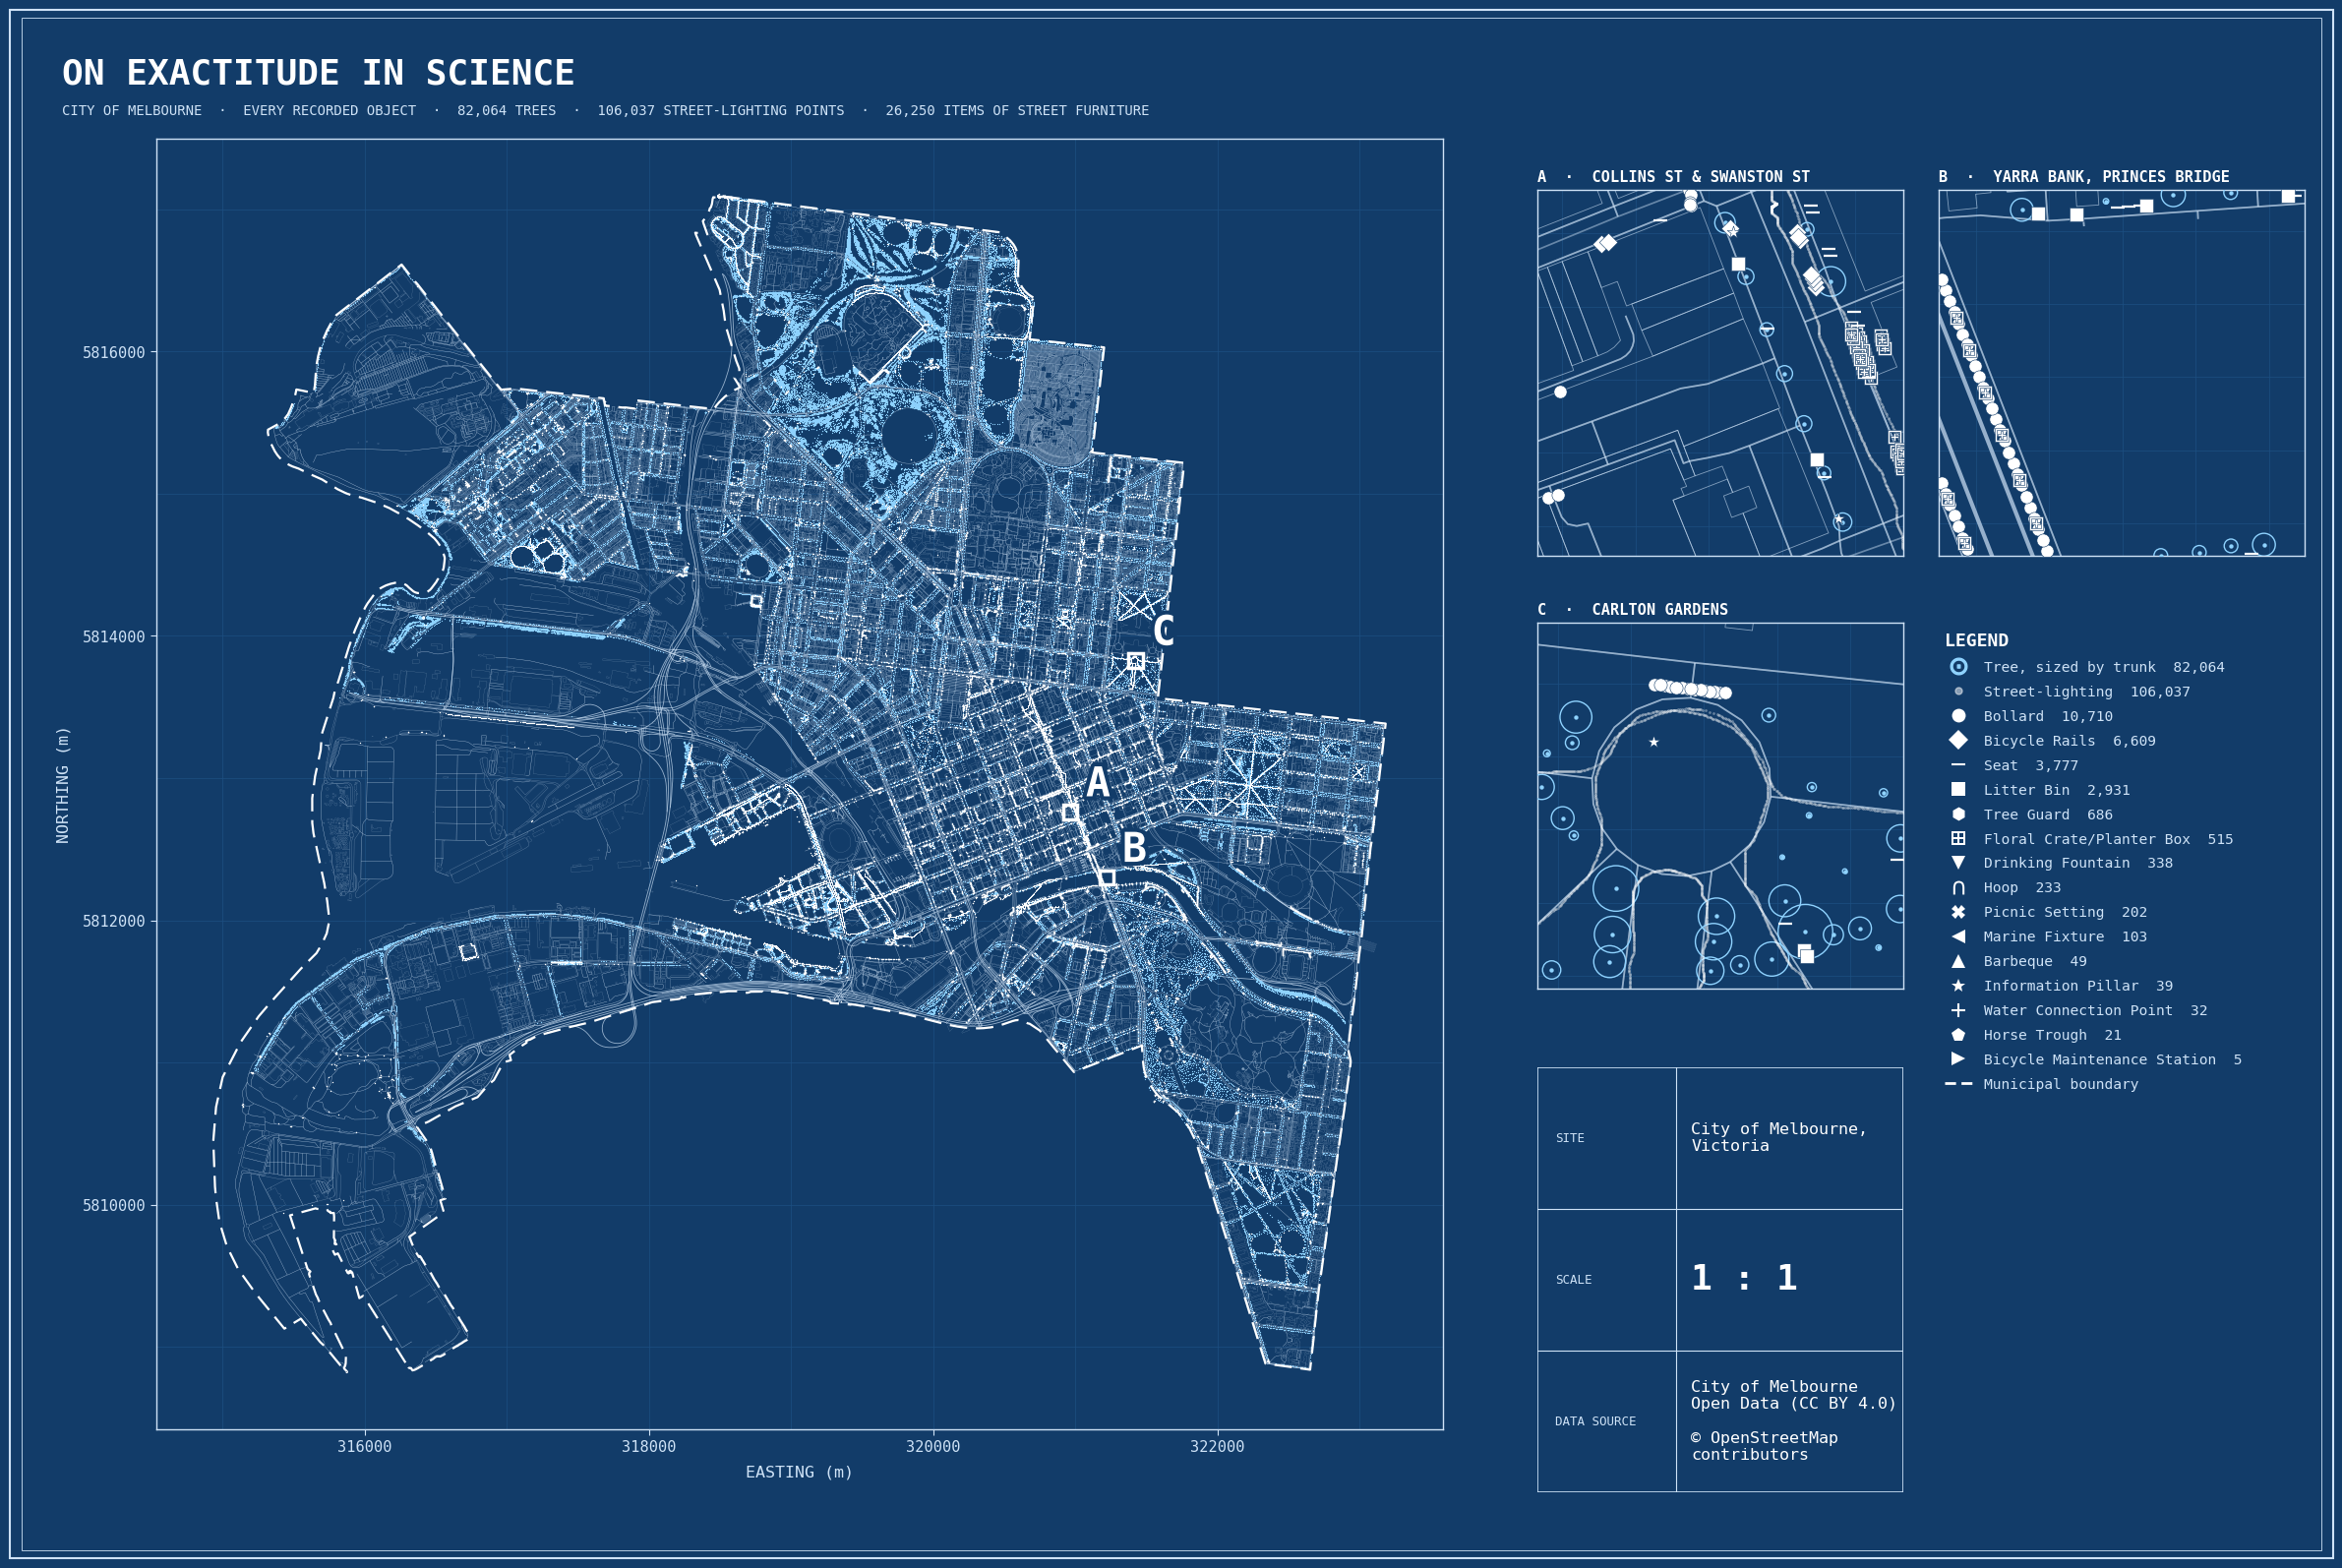

In [42]:
fig = plt.figure(figsize=(24, 16), facecolor=BG)

# outer drawing border (double rule)
for pad, lw in ((.008, 1.5), (.013, .6)):
    fig.add_artist(Rectangle((pad, pad), 1 - 2 * pad, 1 - 2 * pad, transform=fig.transFigure,
                             fill=False, ec=LINE, lw=lw))

# ---- main map
bx0, by0, bx1, by1 = boundary.total_bounds
padm = 400
main_box = (bx0 - padm, by0 - padm, bx1 + padm, by1 + padm)
ax = fig.add_axes([0.055, 0.09, 0.575, 0.82])
blueprint_frame(ax, main_box, grid_step=1000)
draw(ax, main_box, zoom=1)
boundary.boundary.plot(ax=ax, color=INK, linewidth=1.6, linestyle=(0, (8, 4)), zorder=6)
ax.ticklabel_format(useOffset=False, style="plain")
ax.set_xlabel("EASTING (m)", color=LINE, fontsize=12, labelpad=8)
ax.set_ylabel("NORTHING (m)", color=LINE, fontsize=12, labelpad=8)

fig.text(0.03, 0.945, "ON EXACTITUDE IN SCIENCE", color=INK, fontsize=26, weight="bold")
fig.text(0.03, 0.925, f"CITY OF MELBOURNE  ·  EVERY RECORDED OBJECT  ·  "
         f"{len(trees):,} TREES  ·  {len(lights):,} STREET-LIGHTING POINTS  ·  {len(furn):,} ITEMS OF STREET FURNITURE",
         color=LINE, fontsize=10)

# ---- insets
slots = [(0.655, 0.645), (0.825, 0.645), (0.655, 0.37)]
for (key, (label, lat, lon)), (x, y) in zip(INSETS.items(), slots):
    box = inset_box(lat, lon)
    ax.add_patch(Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, ec=INK, lw=2.5, zorder=7))
    ax.text(box[2] + 60, box[3] + 60, key, color=INK, fontsize=30, weight="bold", zorder=8,
            path_effects=[pe.withStroke(linewidth=6, foreground=BG)])
    ia = fig.add_axes([x, y, 0.155, 0.155 * 24 / 16])   # square
    blueprint_frame(ia, box, grid_step=20)
    draw(ia, box, zoom=60)
    boundary.boundary.plot(ax=ia, color=INK, linewidth=1.6, linestyle=(0, (8, 4)), zorder=6)
    ia.set_xticks([]); ia.set_yticks([]); ia.set_xlabel(""); ia.set_ylabel("")
    ia.set_title(f"{key}  ·  {label.upper()}", color=INK, fontsize=11, weight="bold", loc="left", pad=6)

# ---- legend
lg = fig.add_axes([0.825, 0.05, 0.155, 0.55]); lg.axis("off")
rows = [(Line2D([], [], marker=r"$\odot$", ls="", color=TREE, ms=12), f"Tree, sized by trunk  {len(trees):,}"),
        (Line2D([], [], marker="o", ls="", color=INK, alpha=.5, ms=5), f"Street-lighting  {len(lights):,}")]
for k, n in kinds.items():
    m = shape_of[k]
    rows.append((Line2D([], [], marker=m, ls="", color=INK, ms=10, mew=1.5 if m in LINE_ONLY else 0), f"{k}  {n:,}"))
rows.append((Line2D([], [], color=INK, lw=2, ls=(0, (4, 2))), "Municipal boundary"))
lg.legend([h for h, _ in rows], [t for _, t in rows], loc="upper left", frameon=False, fontsize=10.5,
          labelcolor=LINE, ncol=1, handletextpad=.8, labelspacing=.75, borderaxespad=0,
          title="LEGEND", title_fontproperties={"size": 13, "weight": "bold"}, alignment="left")
lg.get_legend().get_title().set_color(INK)

# ---- title block
tb = fig.add_axes([0.655, 0.05, 0.155, 0.27]); tb.set_xlim(0, 1); tb.set_ylim(0, 1); tb.axis("off")
tb.add_patch(Rectangle((0, 0), 1, 1, fill=False, ec=LINE, lw=1.2))
fields = [("SITE", "City of Melbourne,\nVictoria"), ("SCALE", "1 : 1"),
          ("DATA SOURCE", "City of Melbourne\nOpen Data (CC BY 4.0)\n\n© OpenStreetMap\ncontributors")]
h = 1 / len(fields)
for i, (k, v) in enumerate(fields):
    y = 1 - (i + 1) * h
    if i: tb.axhline(y + h, color=LINE, lw=.8)
    tb.text(.05, y + h / 2, k, color=LINE, fontsize=9, va="center")
    tb.text(.42, y + h / 2, v, color=INK, va="center", fontsize=26 if k == "SCALE" else 12,
            weight="bold" if k == "SCALE" else "normal")
tb.axvline(.38, color=LINE, lw=.8)

fig.savefig("melbourne_blueprint.png", dpi=300, facecolor=BG)
print("Saved melbourne_blueprint.png")
plt.show()